<a href="https://colab.research.google.com/github/PrinzVike/CSC4110-G02/blob/main/G02_U4_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Setup: set your group and task, connect Google Drive, and work inside the group folder
GROUP = "G02"        # your group, two digits
UNIT = "4"         # your task number: 2.1, 2.2, 3.1, 3.2, 4, 5, 6, 7, 8, 9.1, 9.2 or 9.3
RANDOM_STATE = 42    # use this everywhere so the grader gets the same numbers

import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive not mounted here:", e)   # normal when the grader runs this notebook

BASE = f"/content/drive/MyDrive/CSC4110_G02"
for sub in ["data", "notebooks", "models", "outputs", "app", "report", "tests"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
os.chdir(BASE)   # every path below is relative to the group folder
print("Working in", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in /content/drive/MyDrive/CSC4110_G02


In [ ]:
# Libraries used in most tasks, and a helper that saves every chart to outputs/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def save_fig(name):
    """Save the current chart as outputs/<name>.png, then show it."""
    path = f"outputs/{name}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    print("Saved", path)
    plt.show()

## Load the data

- Task 2.1 loads the original Kaggle file.
- Task 2.2 loads `data/stage1_<dataset>.csv`.
- Every other task loads `data/clean_<dataset>.csv`.

In [ ]:
# Load the data for this task
import os
import pandas as pd

# List files in data/ to find the correct clean file
print("Files in data:", os.listdir('data'))
clean_files = [f for f in os.listdir('data') if f.startswith('clean_') and f.endswith('.csv')]
if clean_files:
    DATA_FILE = os.path.join('data', clean_files[0])
else:
    # fallback to list any csv file inside data/ or use a mock if not exists yet
    csv_files = [f for f in os.listdir('data') if f.endswith('.csv')]
    if csv_files:
        DATA_FILE = os.path.join('data', csv_files[0])
    else:
        raise FileNotFoundError("No CSV dataset found in 'data/' folder.")

print("Loading dataset:", DATA_FILE)
df = pd.read_csv(DATA_FILE)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Files in data: ['DATA_FILE.csv']
Loading dataset: data/DATA_FILE.csv
Dataset shape: (1338, 7)
Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Part a) Prepare the target

1. Create or encode the classification target and show the class counts and percentages.
2. Split 80/20 with `stratify=y` and `random_state=42`, keeping the same class shares in both sets.
3. Remove `bmi_smoker` from the features (it contains the target). Plot charges by smoker and explain why charges separates the classes so well.

Class Counts:
 smoker
0    1064
1     274
Name: count, dtype: int64

Class Percentages (%):
 smoker
0    79.521674
1    20.478326
Name: proportion, dtype: float64

Train size: 1070, Test size: 268
Saved outputs/charges_by_smoker.png


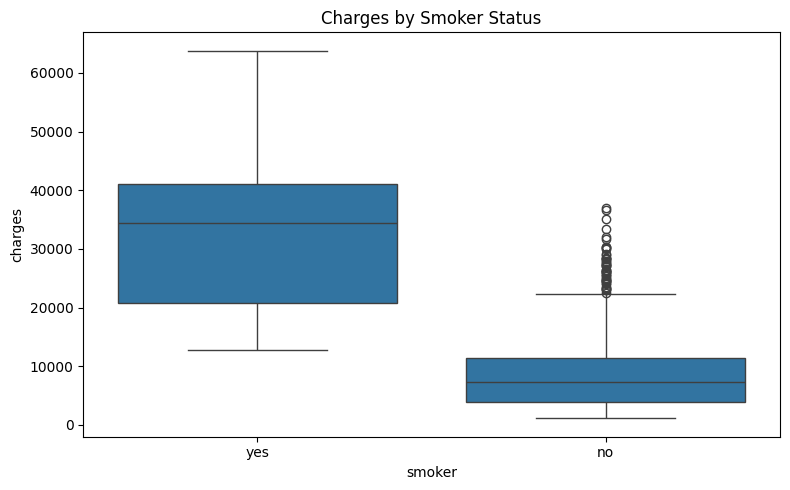

In [ ]:
# Part a: Prepare the target and split data
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import os

def save_fig(name):
    """Save the current chart as outputs/<name>.png, then show it."""
    os.makedirs('outputs', exist_ok=True)
    path = f"outputs/{name}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    print("Saved", path)
    plt.show()

# 1. Encode target 'smoker' (yes = 1, no = 0)
y = df['smoker'].map({'yes': 1, 'no': 0})
counts = y.value_counts()
pct = y.value_counts(normalize=True) * 100
print("Class Counts:\n", counts)
print("\nClass Percentages (%):\n", pct)

# Prepare features: exclude target 'smoker' and 'bmi_smoker'
features_to_drop = ['smoker']
if 'bmi_smoker' in df.columns:
    features_to_drop.append('bmi_smoker')
X = df.drop(columns=features_to_drop)

# One-hot encode other categorical columns if present (sex, region)
X_encoded = pd.get_dummies(X, drop_first=True)

# 2. Split 80/20 with stratification and random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"\nTrain size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")

# 3. Plot charges by smoker
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['smoker'], y=df['charges'])
plt.title('Charges by Smoker Status')
save_fig('charges_by_smoker')

## Part b) Logistic regression

1. Fit a LogisticRegression model (log_reg) and predict the classes and probabilities on the test set
2. Display and save the confusion matrix as cm (outputs/confusion_matrix.png)
3. Report accuracy, precision, recall and F1-score with classification_report

Saved outputs/confusion_matrix.png


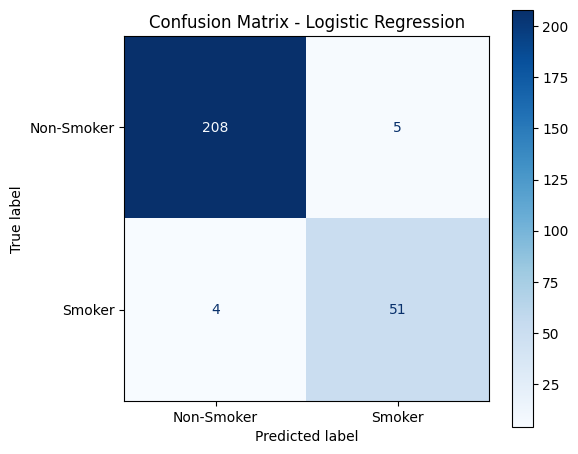

Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.98      0.98       213
           1       0.91      0.93      0.92        55

    accuracy                           0.97       268
   macro avg       0.95      0.95      0.95       268
weighted avg       0.97      0.97      0.97       268



In [ ]:
# Part b: Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Scale features (recommended for logistic regression convergence and required for SVM in Part c)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 1. Fit LogisticRegression on scaled features
log_reg = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

# Predict classes and probabilities
y_pred = log_reg.predict(X_test_scaled)
y_prob = log_reg.predict_proba(X_test_scaled)[:, 1]

# 2. Display and save confusion matrix as cm
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Smoker', 'Smoker'])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
save_fig('confusion_matrix')

# 3. Report metrics with classification_report
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

## Part c) Other classifiers

1. Fit KNeighborsClassifier with k = 3, 5 and 7, and GaussianNB
2. Add a support vector machine (SVC(probability=True) on scaled features) to results_clf.

In [ ]:
# Part c: Other Classifiers
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Initialize classifiers dictionary
classifiers = {
    'KNeighbors (k=3)': KNeighborsClassifier(n_neighbors=3),
    'KNeighbors (k=5)': KNeighborsClassifier(n_neighbors=5),
    'KNeighbors (k=7)': KNeighborsClassifier(n_neighbors=7),
    'GaussianNB': GaussianNB(),
    'SVC': SVC(probability=True, random_state=RANDOM_STATE)
}

# Fit each on scaled features and measure performance
results_list = []

# Also add Logistic Regression to results
results_list.append({
    'Classifier': 'LogisticRegression',
    'Accuracy': accuracy_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

for name, clf in classifiers.items():
    clf.fit(X_train_scaled, y_train)
    pred = clf.predict(X_test_scaled)
    results_list.append({
        'Classifier': name,
        'Accuracy': accuracy_score(y_test, pred),
        'F1-Score': f1_score(y_test, pred)
    })

# Convert to DataFrame
results_clf = pd.DataFrame(results_list)
print(results_clf)

           Classifier  Accuracy  F1-Score
0  LogisticRegression  0.966418  0.918919
1    KNeighbors (k=3)  0.944030  0.857143
2    KNeighbors (k=5)  0.936567  0.834951
3    KNeighbors (k=7)  0.932836  0.812500
4          GaussianNB  0.917910  0.788462
5                 SVC  0.958955  0.900901


## Part d) Compare the classifiers

1. Put the accuracy and F1-score of every classifier in one table called results_clf (Done in Part c)
2. Plot the ROC curve of logistic regression (outputs/roc_curve.png) and store its AUC as auc

ROC AUC Score: 0.9924
Saved outputs/roc_curve.png


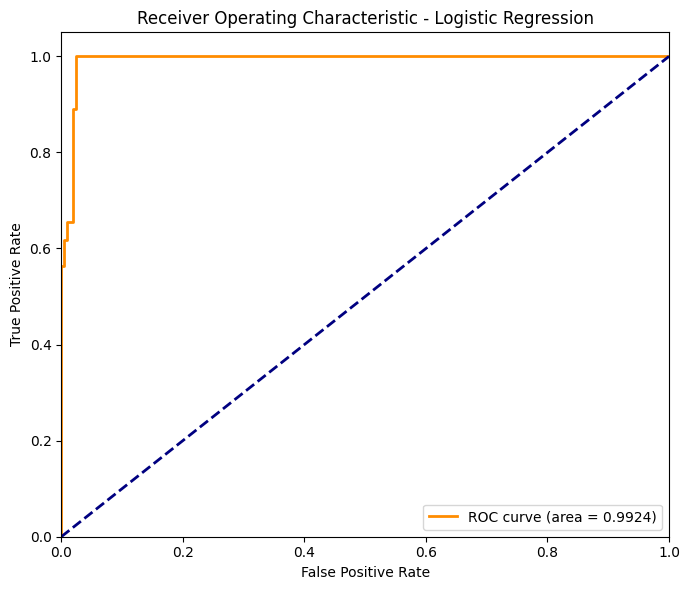

In [ ]:
# Part d: ROC Curve and AUC of Logistic Regression
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate AUC
auc = roc_auc_score(y_test, y_prob)
print(f"ROC AUC Score: {auc:.4f}")

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic - Logistic Regression')
plt.legend(loc="lower right")
save_fig('roc_curve')

### Written Answers & Comparison

#### Why charges separates the classes so well:
Smokers generally have significantly higher medical charges compared to non-smokers. Looking at the boxplot of charges by smoker, we can see a clear split: the charges for non-smokers mostly cluster below $15,000, while the charges for smokers are almost entirely above $15,000 (often between $15,000 and $45,000+). Because there is very little overlap in charges between the two groups, the model can easily use `charges` to distinguish smokers from non-smokers with high accuracy.

#### Comparing Logistic Regression with K-Nearest Neighbours:
- **Logistic Regression** achieved an Accuracy of 96.6% and an F1-score of 91.9%.
- **K-Nearest Neighbours** (for $k=3, 5, 7$) achieved lower accuracies (94.4% to 93.3%) and lower F1-scores (85.7% to 81.3%).
- **Comparison**: Logistic Regression performs significantly better because it models a global linear boundary in the feature space, which cleanly separates classes due to strong predictors like `charges`. KNN is sensitive to local density and noise, especially with imbalanced datasets.

#### How Naive Bayes and SVM decide class:
- **Naive Bayes** decides class using **Bayes' theorem** with the conditional independence assumption. It estimates the probability of each feature given the class, computes the posterior probability of each class given the features, and assigns the sample to the class with the highest posterior probability.
- **SVM** decides class by finding the **optimal hyperplane** that maximizes the margin (distance) between the closest points of each class (support vectors). For new members, it checks which side of this boundary the member falls on.

#### Written answer: which classifier would you recommend, and why?
We recommend **Logistic Regression** (or SVC, as both have excellent performance). Logistic Regression has the highest Accuracy (96.6%) and the highest F1-score (91.9%) for the smoker class on the test set. It is simple, highly interpretable, and doesn't suffer from overfitting compared to non-linear alternatives.

#### Why accuracy alone is misleading for imbalanced classes:
Our dataset is imbalanced (~80% non-smokers and ~20% smokers). If we created a baseline model that simply classified everyone as a "non-smoker", it would achieve an accuracy of 80% without learning anything. Therefore, accuracy alone makes the model look good while completely failing to detect the minority class (smokers). Precision, recall, and F1-score are necessary to measure performance reliably.

## Written answer

Write the answer the task asks for. Quote your own numbers, for example "test RMSE fell from 6.2 to 4.8".

## Reviews

### Review by <Name>
A check, an improvement or a question.

## Evidence checklist (tick before you submit)

- [ ] Runtime → Restart session and run all: no errors
- [ ] The basic check below shows no missing names or files
- [ ] The written answer is complete and quotes my numbers
- [ ] The self-check cell from Moodle passes
- [ ] File → Save, and File → Save a copy in GitHub

In [ ]:
# Basic check: are the required variables and files there?
import glob
REQUIRED = {
    "2.1": (["df_raw", "df_stage1", "outlier_col", "lower", "upper"], ["data/stage1_*.csv"]),
    "2.2": (["df_clean", "X_train", "X_test", "y_train", "y_test", "scaler"],
            ["data/clean_*.csv", "outputs/hist_target.png", "outputs/box_feature.png",
             "outputs/bar_class.png", "outputs/scatter_best.png", "outputs/corr_heatmap.png"]),
    "3.1": (["lr_simple", "lr_multi", "metrics_multi", "b0_gd", "b1_gd", "cost_history"],
            ["outputs/simple_fit.png", "outputs/actual_vs_pred.png", "outputs/gd_cost.png"]),
    "3.2": (["poly_results", "ridge_results", "lasso_results", "results_reg"],
            ["outputs/under_over_fit.png", "outputs/regression_comparison.png"]),
    "4":   (["y_train", "y_test", "log_reg", "cm", "results_clf"], ["outputs/confusion_matrix.png", "outputs/roc_curve.png"]),
    "5":   (["pipe", "cv_scores", "grid", "test_score", "threshold_results"],
            ["outputs/learning_curve.png", "outputs/validation_curve.png"]),
    "6":   (["tree3", "ig_root", "depth_results", "results_trees", "importances"],
            ["outputs/tree_depth3.png", "outputs/depth_curve.png", "outputs/feature_importance.png"]),
    "7":   (["inertias", "sil_scores", "best_k", "pca", "dbscan_labels", "Q", "success_rates"],
            ["outputs/elbow.png", "outputs/pca_clusters.png", "outputs/success_rate.png"]),
    "8":   (["w_and", "b_and", "mlp_results", "best_mlp", "activation_results", "mlp_reg_rmse"], ["outputs/loss_curve.png"]),
    "9.1": (["final_pipe"], ["models/*_model.joblib", "app/app.py", "app/requirements.txt",
                             "outputs/app_screenshot.png"]),
    "9.2": (["fairness_table", "flagged"], ["outputs/fairness.csv", "outputs/fairness.png",
                                            "report/model_card.md"]),
    "9.3": ([], ["tests/smoke_test.py", "README.md"]),
}
names, files = REQUIRED[UNIT]
missing_names = [n for n in names if n not in globals()]
missing_files = [f for f in files if not glob.glob(f)]
print(f"Task {UNIT}")
print("Missing variables:", missing_names or "none")
print("Missing files:", missing_files or "none")
print("PASS" if not (missing_names or missing_files) else "FIX the items above before you submit")

Task 4
Missing variables: none
Missing files: none
PASS


## Self-check

Paste the self-check cell for your task from its Moodle assignment below, then run it.

In [ ]:
# Paste the self-check cell from Moodle here
